In [28]:
import sys
from pathlib import Path
import numpy as np
import yaml
import jax
import gc
from tqdm.notebook import tqdm
from dataclasses import replace
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection

ROOT = Path("/home/kzeleznikar/IJS-F1/Koda/EI_baths")
CFG = ROOT / "config" / "config_phonons.yaml"


import EI.ei_unified as eu
from phase_map_plots import plot_maps, scan_maps
from fixed_baths import (
    plot_bz,
    plot_dispersion,
    plot_energy,
    plot_xi,
    solve_state,
    solve_teff,
)
from utils.cosmetics import apply_plt_style
from utils.logger import logger
from utils.plotting_utils import Plotter
import EI.ei_unified as eu
import EI.ei_jax_2 as ej
import EI.ei_phonon as pb
from EI.ei_anderson import solve_anderson

from utils.logger import logger, tqdm_bar
from utils.plotting_utils import Plotter, plot_cmap, format_ax, add_legend, plot_cmap, plot_phase_diag, color_map
from fixed_baths import k_path, take_path, color_line, solve_state, plot_dispersion


apply_plt_style()
pt = Plotter(show=True, close=False)

from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png", dpi=300)

FIG_PATH = "/home/kzeleznikar/IJS-F1/Notes/latex/figures/"

In [29]:
from matplotlib.colors import SymLogNorm
import matplotlib.pyplot as plt
import colormaps as cmaps
import jax.numpy as jnp
from matplotlib.colors import LogNorm
from matplotlib.colors import Normalize
from utils.cosmetics import SET1_LIST

In [30]:
with CFG.open("r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

md = cfg["model"]
eq = cfg["equilibrium"]
sc = cfg["scan"]
op = cfg["open_system"]
nk = md["nk"]
bp = md["band"]["pars"]
taeV = 0.1
bd = eu.tb_2d(nk["scan"], **bp)
bd_ref = eu.tb_2d(nk["reference"], **bp)
p = eu.MFPars(**md["mean_field"])

In [31]:
s0 = eu.solve_eq(bd_ref, p, **eq["initial"], **eq["solve"])
d0 = max(abs(float(s0.d)), 1.0e-12)
m0 = float(s0.m)
tc = float(eu.critical_temperature(bd_ref, p, **eq["critical"]))

logger.info(f"Delta_0 = {d0} = {d0 * taeV /(8.617 * 1e-5)} K")
logger.info(f"m = {m0}")
logger.info(f"T_c = {tc} = {tc * taeV /(8.617 * 1e-5)} K")

kriticna temp bisekcija:   0%|          | 0/80 [00:00<?, ?it/s]

[09:34:35] [INFO    ] Delta_0 = 0.14470384738527836 = 167.9283362948571 K
[09:34:35] [INFO    ] m = -0.8607308732476676
[09:34:35] [INFO    ] T_c = 0.08171799502323365 = 94.83346294909325 K


In [47]:
tg = sc["temperature"]

tn = np.linspace( tg["min_ratio"], tg["max_ratio"], tg["nt"])

t1a = tn * tc
t2a = tn * tc
nt = tg["nt"]

st = ej.mf_state(bd_ref, p, s0.d, s0.m)
t1n, t2n = 1.2, 0.6
t1, t2 = t1n * tc, t2n * tc

In [48]:
bc = op["bath"]
fn = getattr(pb, bc["rate"])
bp = dict(bc["pars"])
ov = bc["baths"]  # one dict per bath, in the order (T1, T2)

bs = tuple(
    fn(t, bd.k, name=f"bath_{i + 1}", **{**bp, **o})
for i, (t, o) in enumerate(zip((t1, t2), ov))
)

es = {**eq["solve"], "prog": False}
se = eu.solve_eq(
    bd, p,
    t=t2,
    d=max(abs(d0), 1.0e-3),
    m=m0,
    **es,
)

sk = {
    "mix": (0.5, 0.5, 0.1),
    "tol": 1.0e-4,
    "nmax": 5000,
    "chk": 50,
    "prog": True,
    "jtol": 1e-1
}

so = ej.solve_fixed(
    bd, p, se.n.copy(), bs,
    d=float(se.d),
    m=float(se.m),
    **sk,
)


ska = {
    "mix": (0.5, 0.5, 0.1),
    "tol": 1.0e-4,
    "nmax": 5000,
    "chk": 10,
    "prog": True,
} 

sol = solve_anderson(
    bd, p, se.n.copy(), bs,
    d=float(se.d), m=float(se.m),
    mem=4, block=128, **ska,
)

st = ej.mf_state(
    bd, p,
    d=float(so.d),
    m=float(so.m),
)

# so = ej.solve_newton(
#     bd, p, se.n.copy(), bs,
#     d=float(se.d),
#     m=float(se.m),
#     tol=1e-4,
#     nmax=50, 
# )

Fixed EI JAX:   0%|          | 0/100 [00:00<?, ?it/s]

Anderson EI JAX:   0%|          | 0/500 [00:00<?, ?it/s]

In [49]:
logger.info(1-sol.m / so.m)
logger.info(1-abs(sol.d / so.d))
logger.info(f"Delta/Delta_0 = {so.d/d0}")

[09:37:10] [INFO    ] 1.5742825698605856e-07
[09:37:10] [INFO    ] -0.00012604910914171263
[09:37:10] [INFO    ] Delta/Delta_0 = 0.3920348375930907


In [50]:
mu = 0      # source band at p0: 0 = alpha, 1 = beta
for c in bs:
    print(c.name, c.w0, c.qd, c.gam)

kg = np.asarray(bd.k, dtype=float)
pi = np.pi
kt = np.array([0,0]) / bs[0].a0   # X: [pi, 0]; M: [pi, pi], Gamma: [0, 0]

dk = np.asarray(pb._wrap_q(kg - kt, 2 * np.pi / bs[0].a0))
ip = int(np.argmin(np.linalg.norm(dk, axis=1)))
logger.info(ip)  
logger.info(kg[ip])

qk = np.asarray(pb._wrap_q(kg - kg[ip], 2 * np.pi / bs[0].a0))     # q = k - p0 in 1st BZ

assert st.u.shape[0] == bd.size

gfs = [jax.vmap(lambda ik, q, c=c: pb.g_mat(st, c, ik, ip, q)) for c in bs]
gq = np.stack([np.asarray(g(jnp.arange(bd.size), jnp.asarray(qk))) for g in gfs])
# gq: (bath, N, pol, nu, mu), complex

gm = np.sqrt((np.abs(gq) ** 2).sum(axis=2))
# gm: (bath, N, nu, mu), |gm|^2 = sum over TE, TM of |M~|^2

bath_1 0.1 4.442882938158366 0.1
bath_2 0.0 4.442882938158366 0.1


[09:37:11] [INFO    ] 1830
[09:37:11] [INFO    ] [0. 0.]


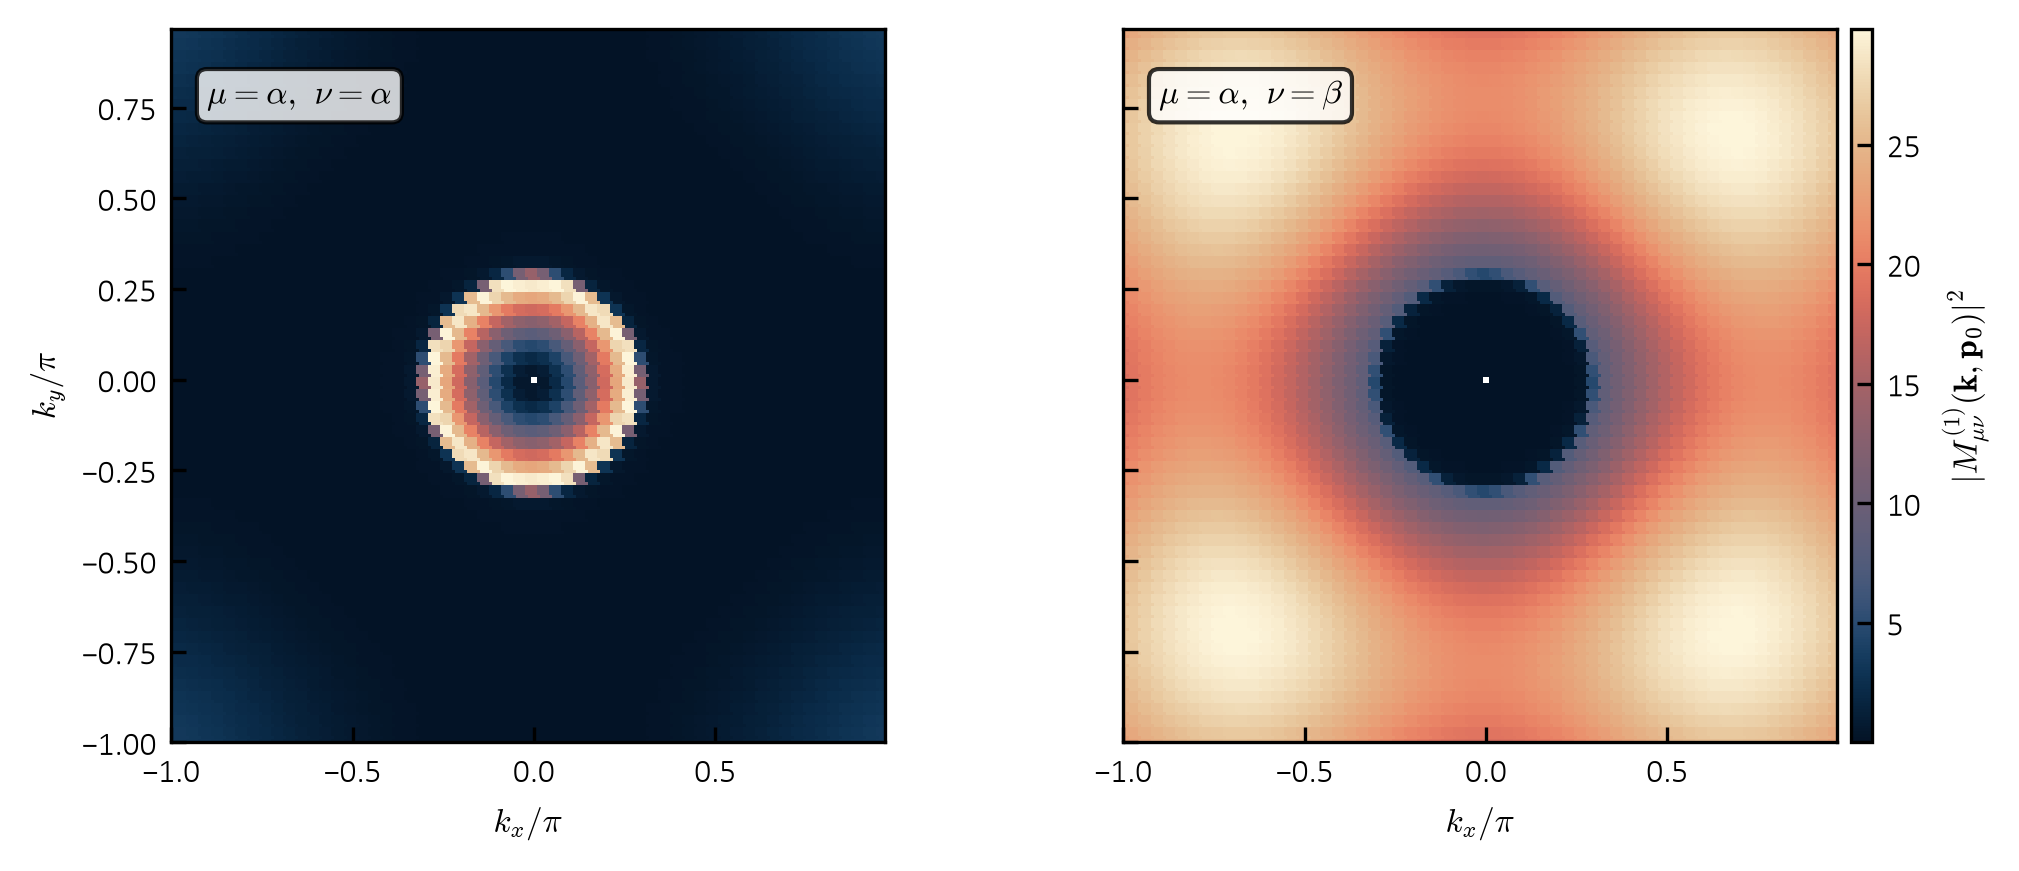

In [51]:
ib = 0    # bath idx
zb = np.abs(gm[ib, :, :, mu]) ** 2    # |G_{mu nu}(k, p0)|^2, shape (N, 2)
zp = zb[zb > 0.0]
norm = LogNorm(vmin=zp.min(), vmax=zp.max())

kx = np.unique(kg[:, 0]) / np.pi
ky = np.unique(kg[:, 1]) / np.pi
bl = (r"\alpha", r"\beta")

with pt.figure(shape=(1, 2), h=0.85, w=2.0, sharex=True, sharey=True) as fg:
    for nu, a in enumerate(fg.ax):
        zz = np.ma.masked_equal(zb[:, nu].reshape(bd.shape).T, 0.0)
        im = color_map(a, kx, ky, zz)
        a.text(0.05, 0.93, rf"$\mu={bl[mu]},\ \nu={bl[nu]}$",
               transform=a.transAxes, ha="left", va="top",
               bbox=dict(boxstyle="round,pad=0.3", fc="white",
                         ec="black", alpha=0.8))
        format_ax(a, x=kx, xlabel=r"$k_x/\pi$", grid=False)
        a.set_aspect("equal")
    fg.ax[0].set_ylabel(r"$k_y/\pi$")
    fg.colorbar(im, rf"$|M^{{({ib + 1})}}_{{\mu\nu}}(\mathbf{{k}},\mathbf{{p}}_0)|^2$",
                ax=fg.ax[-1], external=True)
    # plt.savefig(FIG_PATH + "absM2_d=2.pdf", bbox_inches="tight")

In [52]:
pk = pb.pack(bs)
e = np.asarray(st.e)
de = e - e[mu, ip]
w = np.abs(de)
qm = np.linalg.norm(qk, axis=1)

om = [np.asarray(pb.omega_q(qm, c)) for c in bs]                  # omega_q^(b)
ls = [pb._line(jnp.asarray(w), jnp.asarray(o)[None, :], c.gam, pk)
      for c, o in zip(bs, om)]                                    # (sp, sl) per bath

nb = [np.asarray(pb._bose(jnp.asarray(w), c.t)) for c in bs]
fs = np.stack([np.where(de < 0.0, -1.0 - n, n) for n in nb])   # N_b(Omega), (bath, 2, N)
fb = fs.sum(axis=0)

lz = np.sign(de) * np.stack([np.array(s) for s, _ in ls])      # A_b(Omega) - A_b(-Omega)
lz[:, mu, ip] = np.nan
fb[mu, ip] = np.nan

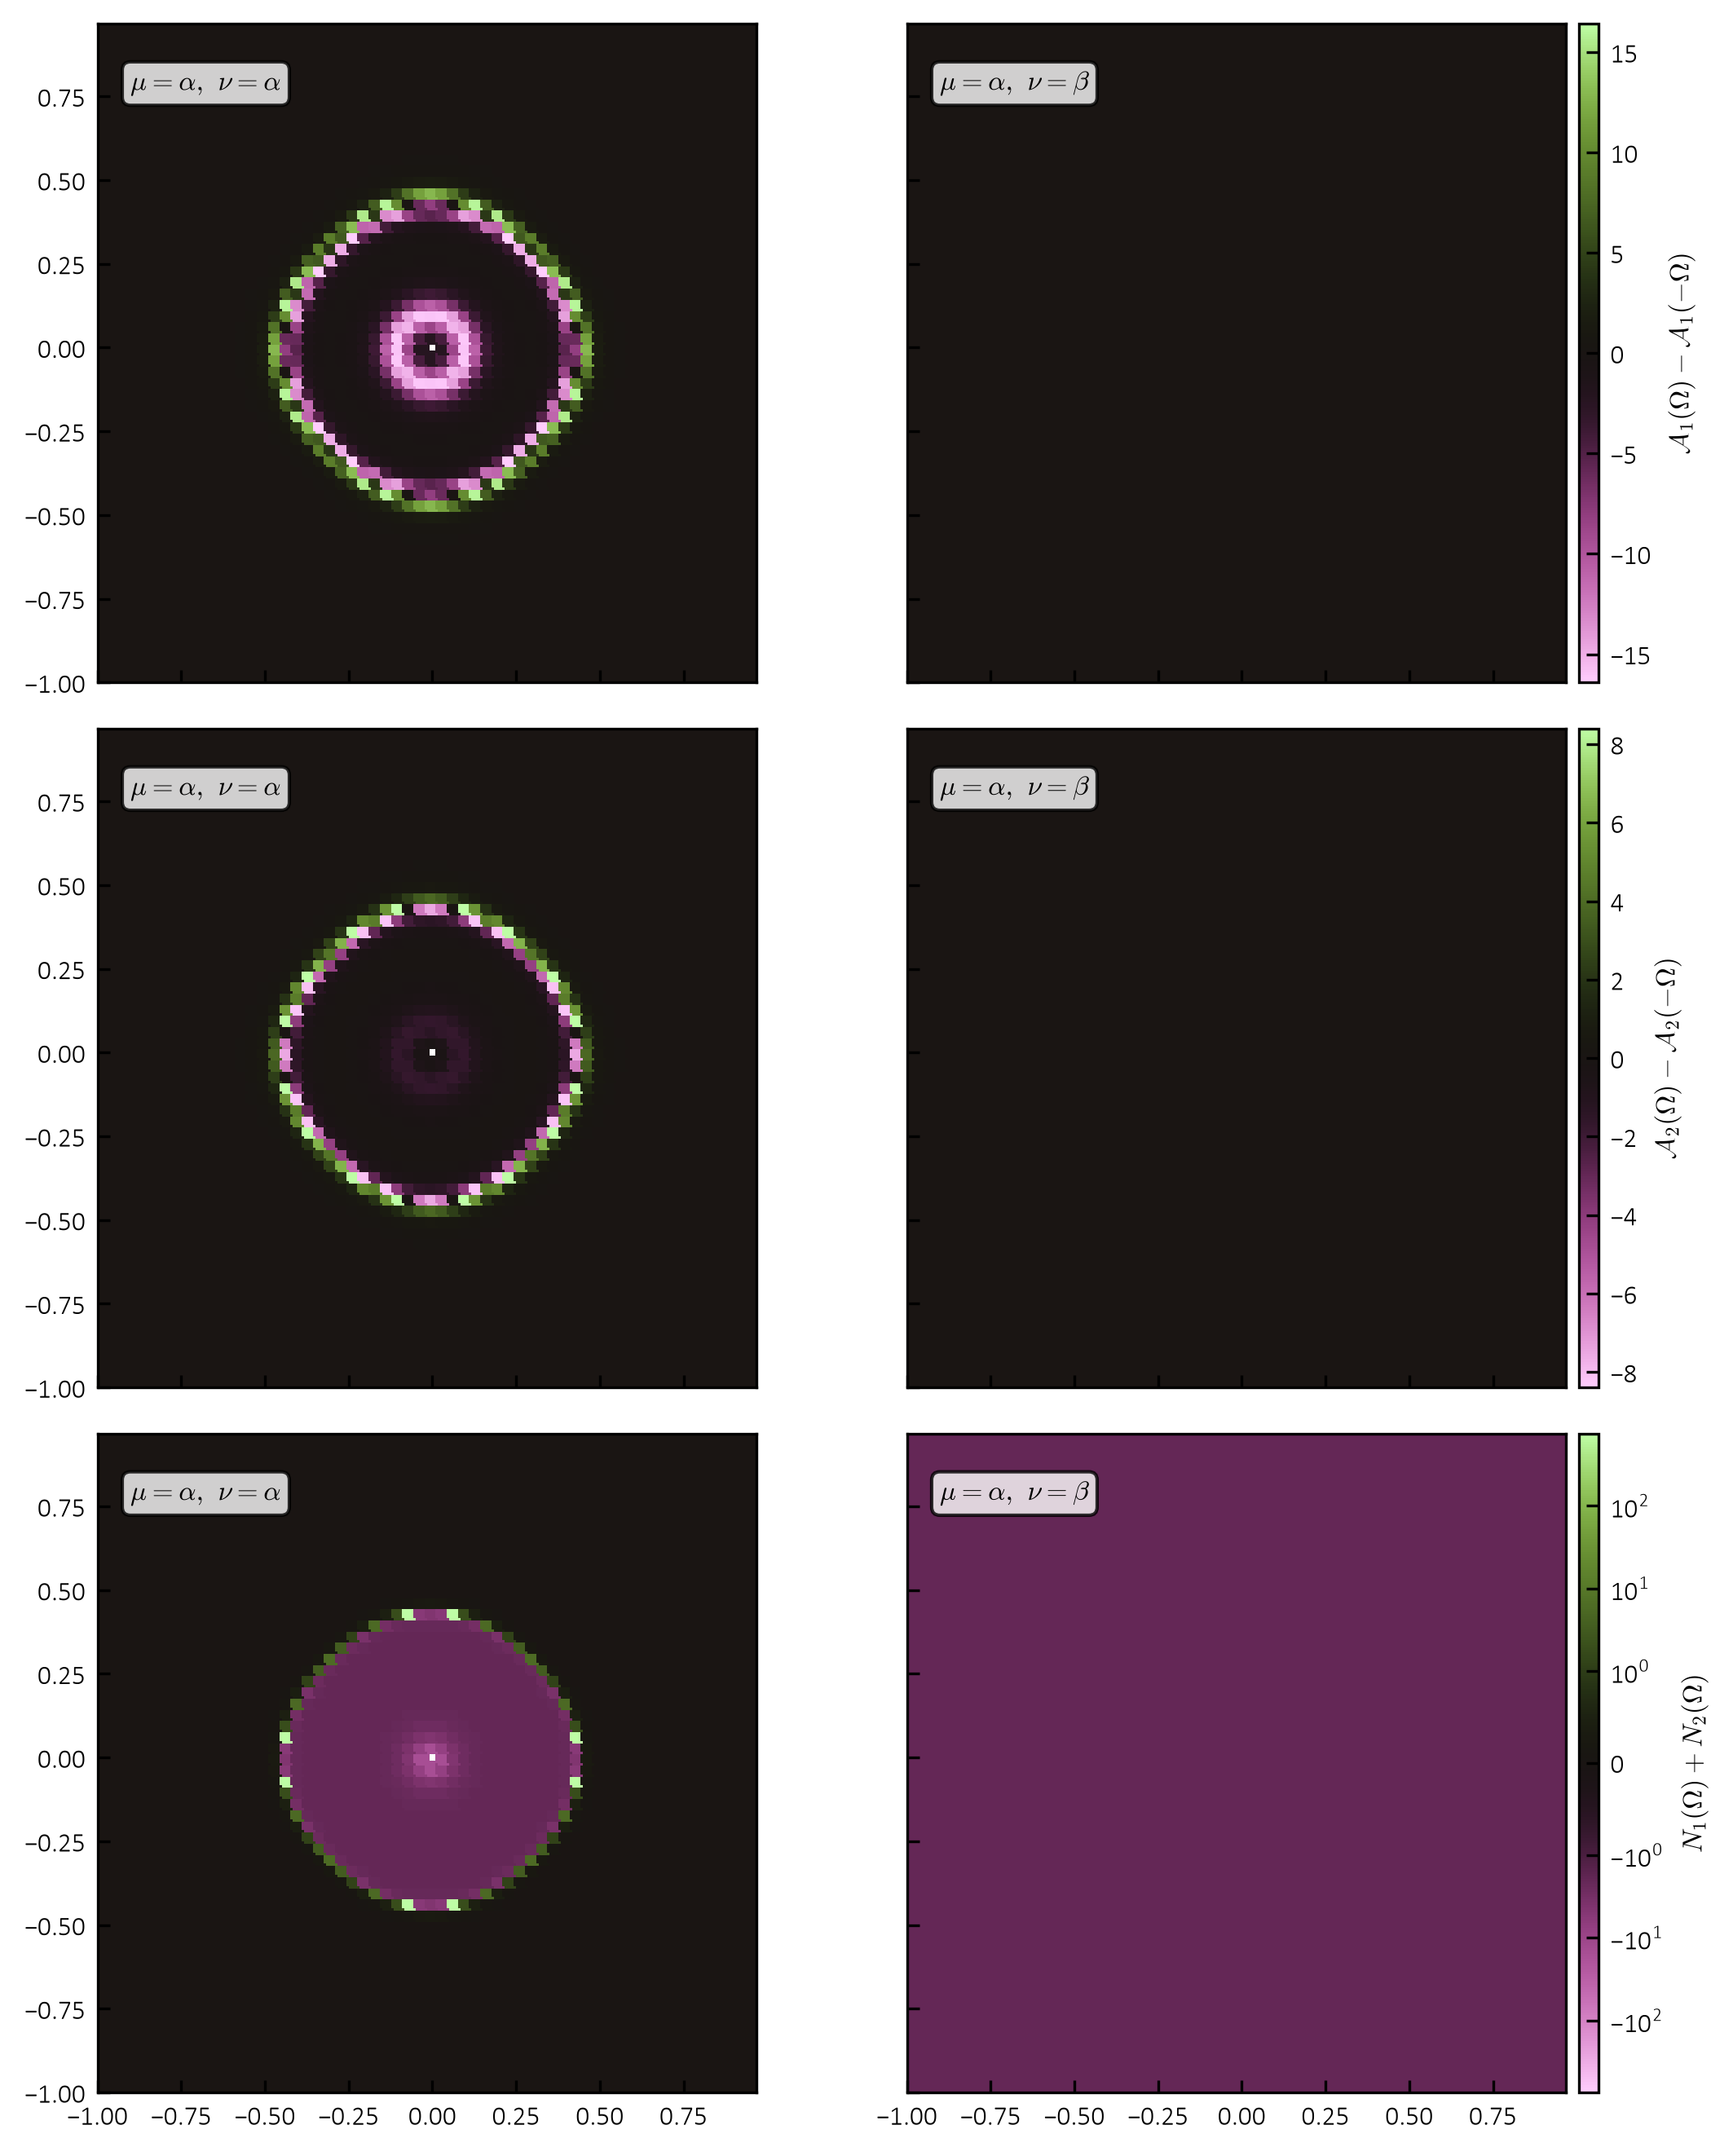

In [53]:
def lnorm(z, dr=1.0e-8):
    """Log norm over positive finite values, floored at dr * max."""
    zp = z[np.isfinite(z) & (z > 0.0)]
    return LogNorm(vmin=max(zp.min(), dr * zp.max()), vmax=zp.max())


def lavg(qk, w, c, nsub=16):
    """Tent average of A(w) - A(-w) over the cell pair around every grid transfer."""
    dkx, dky = 2.0 * np.pi / np.asarray(bd.shape)
    t = 2.0 * ((np.arange(nsub) + 0.5) / nsub - 0.5)    # nodes in [-1, 1]
    wt = (1.0 - np.abs(t)) / np.sum(1.0 - np.abs(t))   # tent weights
    out = np.zeros_like(w)
    for tx, ax in zip(t, wt):
        for ty, ay in zip(t, wt):
            qx = np.mod(qk[:, 0] + tx * dkx + np.pi, 2.0 * np.pi) - np.pi
            qy = np.mod(qk[:, 1] + ty * dky + np.pi, 2.0 * np.pi) - np.pi
            o = np.asarray(pb.omega_q(np.hypot(qx, qy), c))
            out += ax * ay * np.asarray(pb._spec_e(jnp.asarray(w), jnp.asarray(o)[None, :], c.gam))
    return out

def bz_pair(fg, ax, z, norm, lab, cmap=cmaps.lipari):
    """Draw the nu = alpha, beta panels of a (2, N) field over the BZ."""
    for nu, a in enumerate(ax):
        zz = np.ma.masked_invalid(z[nu].reshape(bd.shape).T)
        im = color_map(a, kx, ky, zz, cmap=cmap, norm=norm)
        a.text(0.05, 0.93, rf"$\mu={bl[mu]},\ \nu={bl[nu]}$",
               transform=a.transAxes, ha="left", va="top",
               bbox=dict(boxstyle="round,pad=0.3", fc="white",
                         ec="black", alpha=0.8))
        format_ax(a, x=kx, grid=False)
        a.set_aspect("equal")
    fg.colorbar(im, lab, ax=ax[-1], external=True)



ns_ = bp["nsub"]
la = np.sign(de) * np.stack([lavg(qk, w, c, ns_) for c in bs])   # pure averaged line
la[:, mu, ip] = np.nan

nr = len(bs) + 1
with pt.figure(shape=(nr, 2), h=0.85 * nr, w=2.0, sharex=True, sharey=True) as fg:
    for i in range(len(bs)):
        vm = np.nanmax(np.abs(la[i]))
        bz_pair(fg, fg.ax[i], la[i], Normalize(-vm, vm),
                rf"$\mathcal{{A}}_{i + 1}(\Omega)-\mathcal{{A}}_{i + 1}(-\Omega)$",
                cmap=cmaps.vanimo)
    vm = np.nanmax(np.abs(fb))
    bz_pair(fg, fg.ax[-1], fb, SymLogNorm(1.0, vmin=-vm, vmax=vm),
            r"$N_1(\Omega)+N_2(\Omega)$", cmap=cmaps.vanimo)
    # plt.savefig(FIG_PATH + "bath_components_mixed.pdf", bbox_inches="tight")

In [39]:

# ns_ = 16
# la = np.sign(de) * np.stack([lavg(qk, w, c, ns_) for c in bs])   # pure averaged line
# la[:, mu, ip] = np.nan

In [40]:
# nu = 1                                         # destination band beta, source mu = alpha
# rows = ((lz, "po tockah"), (la, "povprecenje sosedov"))

# with pt.figure(shape=(2, 2), h=1.8, w=2.0, sharex=True, sharey=True) as fg:
#     for i in range(len(bs)):
#         vm = np.nanmax(np.abs(np.stack([z[i, nu] for z, _ in rows])))
#         nm_ = Normalize(vmin=-vm, vmax=vm)
#         for r, (z, nm) in enumerate(rows):
#             a = fg.ax[i, r]
#             zz = np.ma.masked_invalid(z[i, nu].reshape(bd.shape).T)
#             im = color_map(a, kx, ky, zz, cmap=cmaps.vanimo, norm=nm_)
#             a.text(0.05, 0.93, rf"$b={i + 1}$, {nm}", transform=a.transAxes,
#                    ha="left", va="top",
#                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.8))
#             format_ax(a, x=kx, grid=False)
#             a.set_aspect("equal")
#         fg.colorbar(im, rf"$\mathcal{{A}}_{i + 1}(\Omega)-\mathcal{{A}}_{i + 1}(-\Omega)$",
#                     ax=fg.ax[i, -1], external=True)
#     for a in fg.ax[-1]:
#         a.set_xlabel(r"$k_x/\pi$")
#         a.set_xlim(-0.3, 0.3)
#     for a in fg.ax[:, 0]:
#         a.set_ylabel(r"$k_y/\pi$")
#         a.set_ylim(-0.3, 0.3)
#     # plt.savefig(FIG_PATH +"primerjava_potockah_lorentz_grid.pdf", bbox_inches="tight")


# # all destinations against Omega, with the bare line at the dominant w_q
# x = np.abs(de) - om[0][None, :]               # detuning from the own w_q
# xx = np.linspace(-1.0, 1.0, 801)
# g = bs[0].gam
# with pt.figure(h=0.7) as fg:
#     a = fg.ax
#     for r, (z, nm) in enumerate(rows):
#         a.scatter(x.ravel(), np.abs(z[0]).ravel(), s=10, color=SET1_LIST[r],
#                   edgecolors="none", label=nm, zorder=3 - r)
#     a.plot(xx, 2.0 * g / (xx**2 + g**2), color="k", lw=0.8, label=r"$2\gamma/(x^2+\gamma^2)$")
#     format_ax(a, x=xx, xlabel=r"$|\Omega|-\omega_{\mathbf{q}}$", ylabel=r"$|\mathcal{A}(\Omega)-\mathcal{A}(-\Omega)|$")
#     add_legend(a, loc=1)
#     # plt.savefig(FIG_PATH +"primerjava_potockah_lorentz.pdf", bbox_inches="tight")

per bath sum vs total: 0.0
total out rate, averaged / point: 1.004


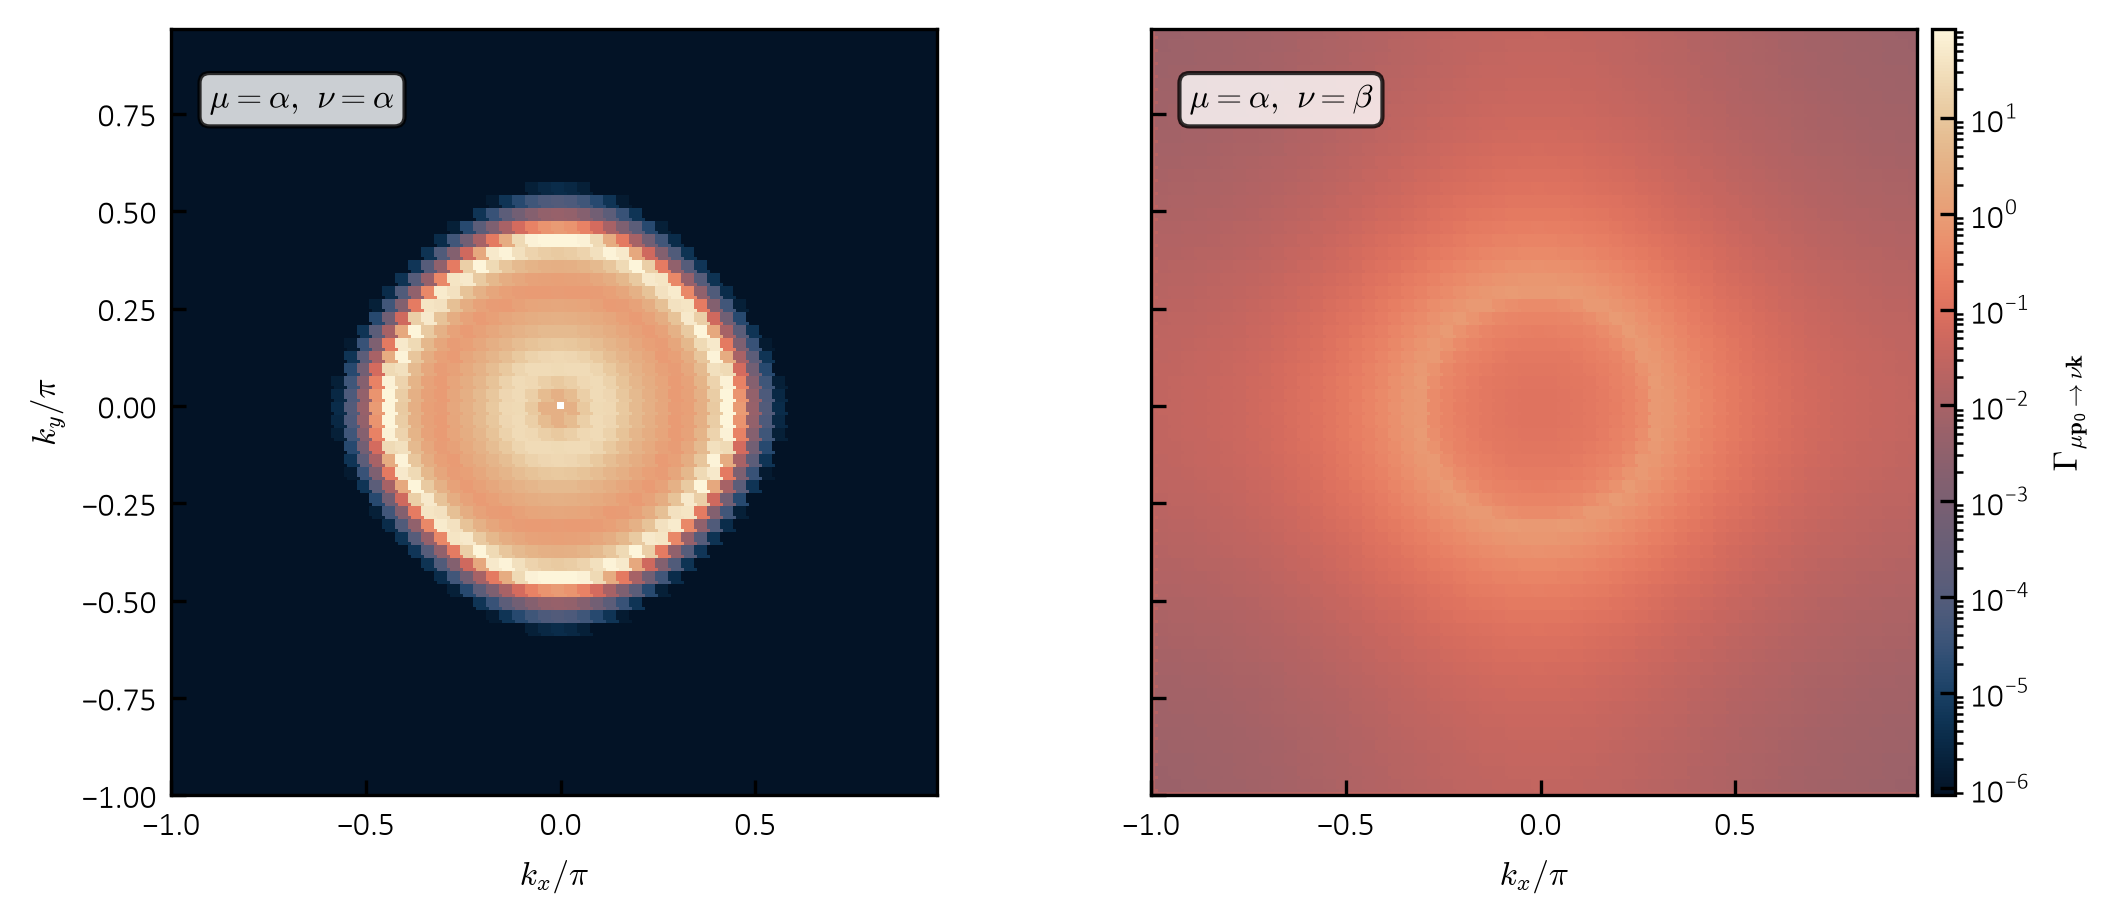

In [54]:
bsa = tuple(replace(c, nsub=ns_) for c in bs)      # cell averaged baths
bs0 = tuple(replace(c, nsub=0) for c in bs)        # point baths, for comparison

gr = np.asarray(pb.source_rates(st, bsa, mu, ip))                             # total Gamma
gb = np.stack([np.asarray(pb.source_rates(st, (c,), mu, ip)) for c in bsa])   # per bath
g0 = np.asarray(pb.source_rates(st, bs0, mu, ip))                             # old point Gamma
g2 = np.abs(gm[:, :, :, mu]).transpose(0, 2, 1) ** 2   # point vertex, (bath, nu, N)
gb[:, mu, ip] = 0.0

print("per bath sum vs total:", np.max(np.abs(gb.sum(axis=0) - gr)) / np.max(gr))
print("total out rate, averaged / point: %.3f" % (gr.sum() / g0.sum()))

gp = gr.copy()
gp[mu, ip] = np.nan
with pt.figure(shape=(1, 2), h=0.85, w=2.0, sharex=True, sharey=True) as fg:
    bz_pair(fg, fg.ax, gp, lnorm(gp),
            r"$\Gamma_{\mu\mathbf{p}_0\to\nu\mathbf{k}}$")
    for a in fg.ax:
        a.set_xlabel(r"$k_x/\pi$")
    fg.ax[0].set_ylabel(r"$k_y/\pi$")
    # plt.savefig(FIG_PATH + "Gamma_d=2_mixed.pdf", bbox_inches="tight")

In [55]:
ij, x, xt = k_path(bd)
sh = bd.shape
tl = [r"$\Gamma$", r"$X$", r"$M$", r"$\Gamma$"]

epa = take_path(e, ij, sh)                 # E_{nu k} 
wq = [take_path(o, ij, sh) for o in om]    # omega_q^(b)
e0 = e[mu, ip]

ms = np.zeros_like(de, dtype=bool)         
ms[mu, ip] = True


def on_path(z):
    """Take a (2, N) field onto the path, with the self term as NaN."""
    z = np.where(ms, np.nan, np.asarray(z, dtype=float))
    return take_path(z, ij, sh)


def cross(y, lv):
    """Path positions where y crosses lv (linear interpolation)."""
    d = y - lv
    i = np.where(np.sign(d[:-1]) * np.sign(d[1:]) < 0)[0]
    return x[i] - d[i] * (x[i + 1] - x[i]) / (d[i + 1] - d[i])

def roll_path(y, im):
    """start path at M, drop duplicate Gamma"""
    y = np.asarray(y)
    return np.concatenate((y[..., im:], y[..., 1:im + 1]), axis=-1)

im = int(np.argmin(np.abs(x - xt[2])))     # index of M
lx = x[-1] - x[im]                         # length M -> Gamma
x = np.r_[x[im:] - x[im], x[1:im + 1] + lx]


wq = [roll_path(w, im) for w in wq]
xt = [0.0, lx, lx + xt[1], x[-1]]
tl = [tl[2], tl[0], tl[1], tl[2]]          # M, Gamma, X, M

yg, yl, yf, yb = (np.stack([on_path(z) for z in zz]) for zz in (g2, la, fs, gb))
yr = on_path(gr)                           # total averaged Gamma, (2, L)
y0 = on_path(g0)                           # total point Gamma, for comparison

bcl = (SET1_LIST[2], SET1_LIST[3])     # bath colours in panel 1
bst = ("-", "--")                      # bath line styles, panels 2-4
pst = (":", "-.")                      # bath line styles, panel 5
dea = epa - e0                         # Delta E on the path, (2, L)


eh = np.stack((take_path(st.eah, ij, bd.shape),
               take_path(st.ebh, ij, bd.shape))) - e0

dea, yr, y0, eh = (roll_path(z, im) for z in (dea, yr, y0, eh))

In [56]:


rows = (
    (yg, r"$\sum_\lambda|\widetilde{M}^{(b),\lambda}_{\nu\mu}|^2$", False),
    (yl, r"$\overline{\mathcal{A}_{b}(\Omega)-\mathcal{A}_{b}(-\Omega)}$", False),
    (yf, r"$N_b(\Omega)$", True),
)
cn = lnorm(gr)

# with pt.figure(shape=(5, 1), h=3.0, w=1.2, sharex=True) as fg:
#     a = fg.ax[0]
#     for ib, c in enumerate(bs):
#         for s in (1.0, -1.0):
#             lv = s * wq[ib]
#             a.fill_between(x, lv - c.gam, lv + c.gam,
#                            color=bcl[ib], alpha=0.15, lw=0)
#             a.plot(x, lv, color=bcl[ib], ls=":", lw=1.0,
#                    label=rf"$\pm\omega^{{({ib + 1})}}_\mathbf{{q}}$" if s > 0 else None)
#             for nu in range(2):
#                 xc = cross(dea[nu], lv)
#                 a.scatter(xc, np.interp(xc, x, lv), color=bcl[ib], s=12,
#                           edgecolors="k", linewidths=0.4, zorder=6)
#     a.scatter([], [], color="0.6", s=12, edgecolors="k", linewidths=0.4,
#               label=r"$|\Omega|=\omega_\mathbf{q}$")
#     for nu, sty in enumerate(("-", "--")):
#         cv = np.nan_to_num(yr[nu], nan=cn.vmin)
#         lc = color_line(a, x, dea[nu], cv, np.full_like(x, 0.4),
#                         cmaps.lipari, cn, ls=sty,
#                         label=rf"$E_{{{bl[nu]}\mathbf{{k}}}} - E_{{{bl[mu]}\mathbf{{p}}_0}}$")
#     yy = np.r_[dea.ravel(), np.concatenate(wq), -np.concatenate(wq)]
#     dy = 0.04 * (np.nanmax(yy) - np.nanmin(yy))
#     format_ax(a, x=x, ylabel=r"$\Omega$",
#               ylim=(np.nanmin(yy) - dy, np.nanmax(yy) + dy), xticks=xt)
#     a.set_ylim(min(dea[1]) *1.05, 1.05 *max(dea[0]))
#     add_legend(a, top=True, ncol=3, fontsize=7)
#     fg.colorbar(lc, fr"$\Gamma_{{{bl[mu]}\mathbf{{p}}_0\to\nu\mathbf{{k}}}}$",
#                 ax=a, external=True)

#     for a, (y, lab, lg) in zip(fg.ax[1:4], rows):
#         for ib in range(len(bs)):
#             for nu in range(2):
#                 a.plot(x, y[ib, nu], color=SET1_LIST[nu], ls=bst[ib], lw=1.1,
#                        label=rf"$\nu={bl[nu]},\ b={ib + 1}$")
#         # if lg:
#             # a.set_yscale("log")
#             # a.set_ylim(1.0e-8 * np.nanmax(y), 2.0 * np.nanmax(y))
#         format_ax(a, x=x, ylabel=lab, xticks=xt)
#         add_legend(a, ncol=2, fontsize=6)

#     fg.ax[1].set_yscale("log")

#     a = fg.ax[4]
#     for nu in range(2):
#         a.plot(x, yr[nu], color=SET1_LIST[nu], lw=1.0,
#                label=rf"$\nu={bl[nu]}$, skupno")
#         # a.plot(x, y0[nu], color="gray", ls="-", lw=0.6,
#         #        label=rf"$\nu={bl[nu]}$, po tockah" if nu == 0 else None)
#     a.set_yscale("log")
#     # a.set_ylim(1.0e-8 * np.nanmax(yr), 2.0 * np.nanmax(yr))
#     format_ax(a, x=x, ylabel=fr"$\Gamma_{{{bl[mu]}\mathbf{{p}}_0\to\nu\mathbf{{k}}}}$",
#               xticks=xt)
    # add_legend(a, ncol=3, fontsize=6)

    # for a in fg.ax:
    #     a.axvline(xt[1], color="0.75", lw=0.7)
    #     a.axvline(xt[2], color="0.75", lw=0.7)
    # fg.ax[-1].set_xticklabels(tl)
    # fg.ax[-1].set_xlabel(r"$\mathbf{k}$")
    # fg.layout((0, 0, 1, 0.95))
    # # plt.savefig(FIG_PATH + "GamXM_path_bath_d=2_mixed.pdf", bbox_inches="tight")

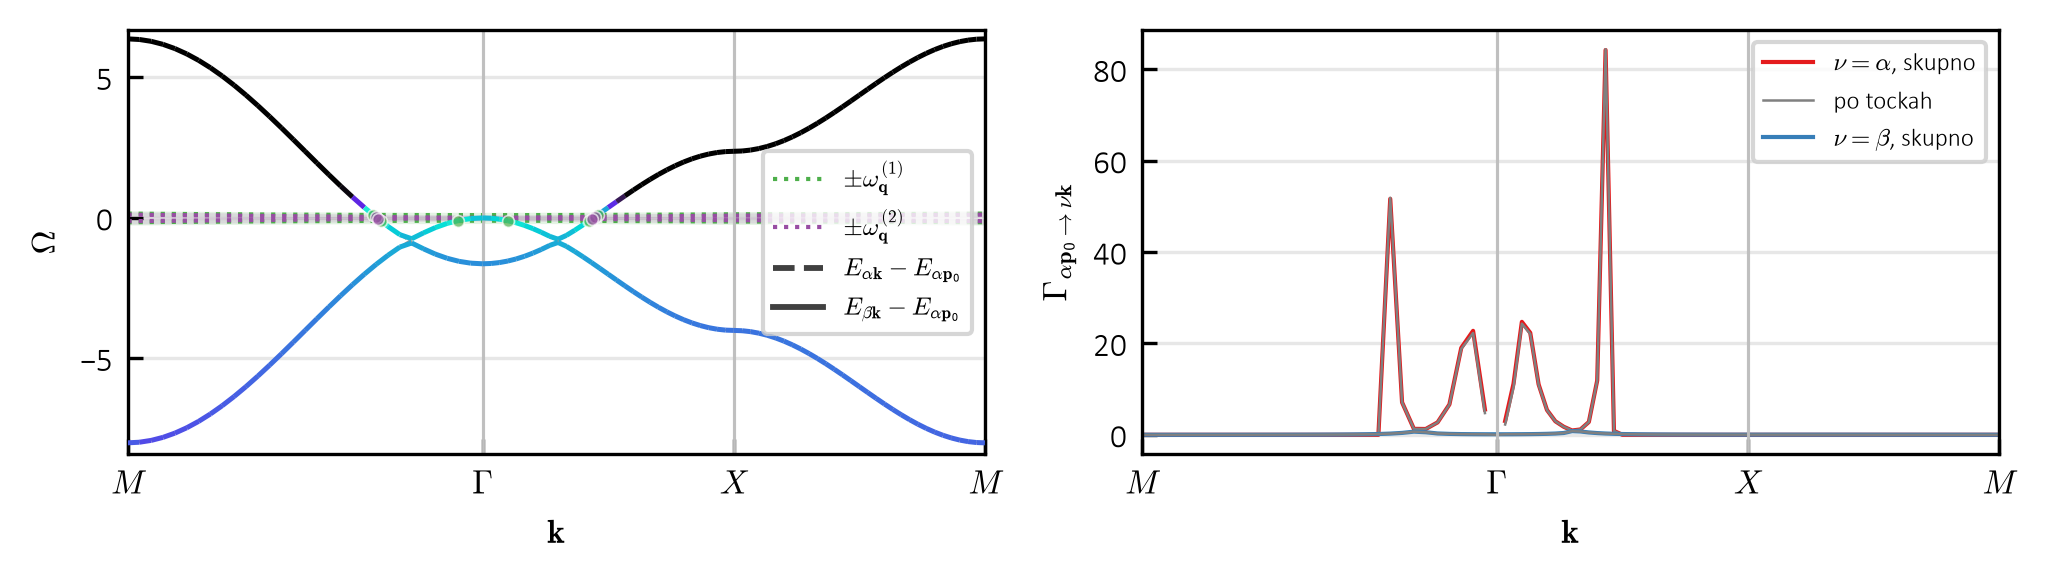

In [57]:
bcl = (SET1_LIST[2], SET1_LIST[3])     # bath colours in panel 1
cn = lnorm(gr)


with pt.figure(shape=(1, 2), h=.6, w=2.0, sharex=True) as fg:
    a = fg.ax[0]
    for ib, c in enumerate(bs):
        for s in (1.0, -1.0):
            lv = s * wq[ib]
            a.fill_between(x, lv - c.gam, lv + c.gam,
                           color=bcl[ib], alpha=0.15, lw=0)
            a.plot(x, lv, color=bcl[ib], ls=":", lw=1.0,
                   label=rf"$\pm\omega^{{({ib + 1})}}_\mathbf{{q}}$" if s > 0 else None)
            for nu in range(2):
                xc = cross(dea[nu], lv)
                a.scatter(xc, np.interp(xc, x, lv), color=bcl[ib], s=8,
                          edgecolors="white", linewidths=0.4, zorder=6, alpha=0.7)
    a.scatter([], [], color="0.2", s=8, edgecolors="white", linewidths=0.5)
    for nu, sty in enumerate(("--", "-")):
        cv = np.nan_to_num(yr[nu], nan=cn.vmin)
        lc = color_line(a, x, dea[nu], cv, np.full_like(x, 0.4),
                        cmaps.cosmic, cn, ls=sty,
                        label=rf"$E_{{{bl[nu]}\mathbf{{k}}}} - E_{{{bl[mu]}\mathbf{{p}}_0}}$")
        a.plot(x, eh[nu], color="0.6", ls=sty, lw=0.5, zorder=1)

    yy = np.r_[dea.ravel(), np.concatenate(wq), -np.concatenate(wq)]
    dy = 0.04 * (np.nanmax(yy) - np.nanmin(yy))
    format_ax(a, x=x, ylabel=r"$\Omega$",
              ylim=(np.nanmin(yy) - dy, np.nanmax(yy) + dy), xticks=xt)
    a.set_ylim(min(dea[1]) *1.05, 1.05 *max(dea[0]))
    # a.set_ylim(-1.5*.05, .05)
    # add_legend(a, fontsize=7, loc="center", ncol=2)
    add_legend(a, fontsize=6, loc=5, ncol=1)

    a = fg.ax[1]
    for nu in range(2):
        a.plot(x, yr[nu], color=SET1_LIST[nu], lw=1.0,
               label=rf"$\nu={bl[nu]}$, skupno")
        a.plot(x, y0[nu], color="gray", ls="-", lw=0.6,
               label=rf"po tockah" if nu == 0 else None)
    # a.set_yscale("log")
    # a.set_ylim(1.0e-8 * np.nanmax(yr), 2.0 * np.nanmax(yr))
    format_ax(a, x=x, ylabel=rf"$\Gamma_{{{bl[mu]}\mathbf{{p}}_0\to\nu\mathbf{{k}}}}$",
              xticks=xt)
    add_legend(a, ncol=1, fontsize=6)

    for a in fg.ax:
        a.axvline(xt[1], color="0.75", lw=0.7)
        a.axvline(xt[2], color="0.75", lw=0.7)
    fg.ax[-1].set_xticklabels(tl)
    fg.ax[0].set_xlabel(r"$\mathbf{k}$")
    fg.ax[-1].set_xlabel(r"$\mathbf{k}$")
    fg.layout((0, 0, 1, 0.95))
    # plt.savefig(FIG_PATH + "GamXM_path_BEC_nadTc.pdf", bbox_inches="tight")

In [18]:
# n = int(round(np.sqrt(len(kg))))
# dk = 2 * np.pi / (n * bs[0].a0)
# ij = np.rint((kg - kg.min(axis=0)) / dk).astype(int) % n   # integer grid coords
# lut = np.empty((n, n), dtype=int)
# lut[ij[:, 0], ij[:, 1]] = np.arange(len(kg))
# g0 = np.rint(-kg.min(axis=0) / dk).astype(int)             # coords of k = 0
# h = n // 2

# qp = np.array([(h - j, h - j) for j in range(h)] + [(j, 0) for j in range(h)]
#               + [(h, j) for j in range(h + 1)])
# x = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(qp, axis=0), axis=1))] * dk
# xt = [0.0, x[h], x[2 * h], x[-1]]
# qm = np.linalg.norm(qp, axis=1) * dk
# wq = [np.asarray(pb.omega_q(qm, c)) for c in bs]
# pa = np.array([(a, b) for a in range(h + 1) for b in range(h + 1)])
# ip = lut[(g0[0] + pa[:, 0]) % n, (g0[1] + pa[:, 1]) % n]
# ik = lut[(g0[0] + pa[:, 0, None] + qp[None, :, 0]) % n,
#          (g0[1] + pa[:, 1, None] + qp[None, :, 1]) % n]
# om = e[:, ik] - e[mu, ip][None, :, None]
# s0 = np.cos(kg[ip, 0]) + np.cos(kg[ip, 1])
# norm = Normalize(vmin=s0.min(), vmax=s0.max())
# sm = ScalarMappable(norm=norm, cmap=cmaps.bubblegum)
# fig, ax = plt.subplots(figsize=(3.47412, 0.8 * 3.47412))
# for nu, ls in enumerate(("--", "-")):
#     seg = np.stack((np.broadcast_to(x, om[nu].shape), om[nu]), axis=-1)
#     ax.add_collection(LineCollection(seg, colors=cmaps.bubblegum(norm(s0)),
#                                      lw=0.3, alpha=0.3, linestyles=ls))
# for ib, c in enumerate(bs):
#     for sg in (1.0, -1.0):
#         ax.fill_between(x, sg * wq[ib] - c.gam, sg * wq[ib] + c.gam,
#                         color=SET1_LIST[ib], alpha=0.2, lw=0)
#         ax.plot(x, sg * wq[ib], color=SET1_LIST[ib], ls="--", lw=1.0,
#                 label=rf"$\pm\omega^{{({ib + 1})}}_\mathbf{{q}}$" if sg > 0 else None)
# ax.plot([], [], "k--", lw=0.6, label=r"$\nu=\alpha$")
# ax.plot([], [], "k-", lw=0.6, label=r"$\nu=\beta$")
# cbar = fig.colorbar(sm, ax=ax)
# cbar.set_label(r"$s(\mathbf{p}_0)$", rotation=90, labelpad=5)
# ax.set_xticks(xt, [r"$M$", r"$\Gamma$", r"$X$", r"$M$"])
# for v in xt[1:3]:
#     ax.axvline(v, color="0.75", lw=0.7)
# ax.set_xlim(x[0], x[-1])
# ax.set_ylim(np.nanmin(om) - 0.3, np.nanmax(om) + 0.3)
# ax.set_xlabel(r"$\mathbf{q} = \mathbf{k} - \mathbf{p}_0$")
# ax.set_ylabel(r"$E_{\nu,\mathbf{p}_0+\mathbf{q}} - E_{\mu\mathbf{p}_0}$")
# ax.grid(alpha=0.3)
# ax.tick_params(which="both", direction="in")
# ax.legend(bbox_to_anchor=(0, 1.02, 1, 0.2), loc="lower left", mode="expand",
#           borderaxespad=0, ncol=4, fontsize=6)
# plt.tight_layout()

In [19]:
# def res_cross(e, bd, b, ij):
#     """On shell crossings |E_nu k - E_mu p| = omega_q for p on the path."""
#     sh = bd.shape
#     kg = np.asarray(bd.k).reshape(sh + (2,))
#     eg = np.asarray(e).reshape((2,) + sh)
#     pi, qa, wa = [], [], []
#     for n, (i0, j0) in enumerate(ij):
#         q = np.mod(kg - kg[i0, j0] + np.pi, 2 * np.pi) - np.pi
#         qm = np.hypot(q[..., 0], q[..., 1])
#         om = np.hypot(b.w0, b.cs * qm)
#         for mu in range(2):
#             for nu in range(2):
#                 f = np.abs(eg[nu] - eg[mu, i0, j0]) - om
#                 for ax in (0, 1):
#                     g = np.roll(f, -1, axis=ax)
#                     c = f * g < 0
#                     t = f[c] / (f[c] - g[c])        # position inside the edge
#                     q2 = np.roll(qm, -1, axis=ax)[c]
#                     o2 = np.roll(om, -1, axis=ax)[c]
#                     qa.append(qm[c] + t * (q2 - qm[c]))
#                     wa.append(om[c] + t * (o2 - om[c]))
#                     pi.append(np.full(c.sum(), n))
#     return np.concatenate(pi), np.concatenate(qa), np.concatenate(wa)


# ib = 1                                         # bath
# sh = bd.shape
# ia = np.argwhere(np.ones(sh, dtype=bool))      # all p in the BZ
# pr, qr, wr = res_cross(e, bd, bs[ib], ia)

# kg = np.asarray(bd.k).reshape(sh + (2,))
# sp = np.cos(kg[..., 0]) + np.cos(kg[..., 1])
# xs = sp[ia[:, 0], ia[:, 1]][pr]                # s of the initial p, per crossing
# se = np.linspace(-2.0, 2.0, 41)                # s bins
# nps, _ = np.histogram(sp.ravel(), se)          # number of p per s bin

# for y, y0, yl, nm in ((qr, 0.0, r"$|\mathbf{q}|$", "res_q_all"),
#                       (wr, bs[ib].w0, r"$\omega_{\mathbf{q}}$", "res_w_all")):
#     ye = np.linspace(y0, y.max(), 31)
#     h, _, _ = np.histogram2d(xs, y, bins=(se, ye))
#     h = h / np.maximum(nps, 1)[:, None]        # crossings per initial p
#     with pt.figure(name=nm, h=0.6) as q:
#         im_ = color_map(q.ax, se, ye, np.where(h >= 0, h, np.nan).T,
#                         cmap=cmaps.lipari)
#         q.colorbar(im_, r"$N_{\mathrm{res}}/N_{\mathbf{p}}$", ax=q.ax)
#         format_ax(q.ax, x=se, xlabel=r"$s_{\mathbf{p}}=\cos p_x+\cos p_y$",
#                   ylabel=yl, grid=False)

In [58]:
import dataclasses
import EI.eff_T as et

et.ej = ej      # route eff_T through ei_jax_2 in this kernel
mc = 0.0        # chemical potential; ei_jax_2 energies already carry -V/2
ep = {
    "dt": 0.1, "mix": [0.1, 0.1], "tol": 1.0e-4,
    "nmax": 20, "chk": 10, "mf": False, "prog": True,
    "mode": "dense", "block": 1024,
}


sf = solve_teff(bd, p, bs, so, t1, t2, mc, op, ep)
sf = dataclasses.replace(sf, st=so.st)   # same d, m since mf=False

logger.info("Delta = %.6f, m = %.6f", so.d, so.m)
logger.info("T_eff/T_c = %.6f, power = %.3e, ok = %s",
            sf.t / tc, sf.power, sf.ok)

Effective temperature:   0%|          | 0/20 [00:00<?, ?it/s]

[09:37:39] [WARNING ] Effective-temperature solver did not converge: err = 3.969e-03
[09:37:39] [INFO    ] Delta = 0.056729, m = -0.862661
[09:37:39] [INFO    ] T_eff/T_c = 0.934550, power = 1.107e-06, ok = False


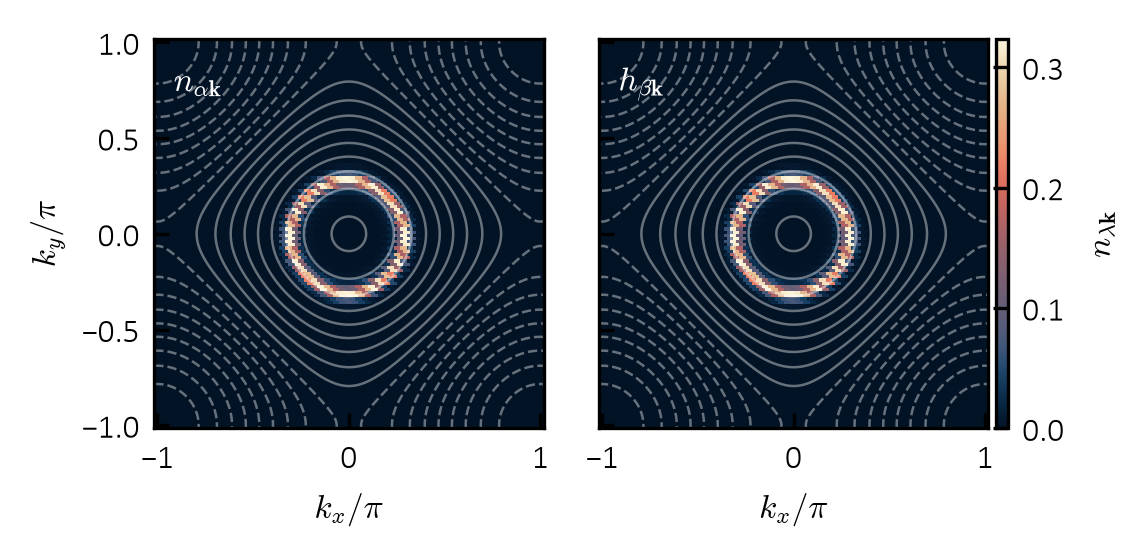

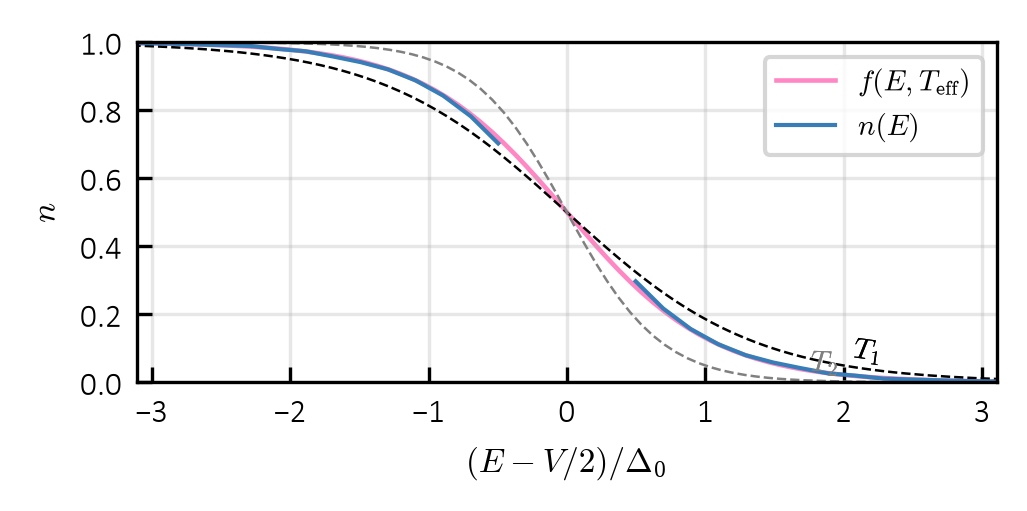

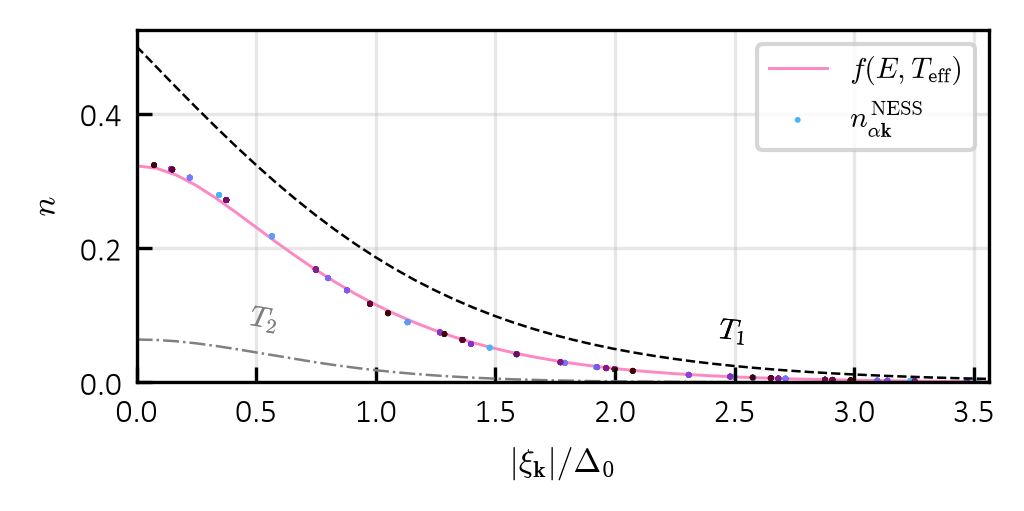

In [60]:
# plot_dispersion(pt, bd, so, mc)                 # bands on Gamma-X-M, coloured by n
plot_bz(pt, bd, so, path=None)                             # 2D n_alpha, n_beta
plot_energy(pt, so, sf, t1, t2, mc, d0, path=None, nb=500)         # n vs E against FD at T1, T2, T_eff
plot_xi(pt, bd, p, eq, so, sf, bs, t1, t2, d0, path=None, nb=100)      # n vs |xi| against FD at T1, T2, T_eff

In [22]:
# eg = np.linspace(0.05, 8.0, 400)          # energy transfer grid
# dn, up = 0.0, 0.0
# for c in bs:
#     a = np.asarray(pb._spec_e(jnp.asarray(eg), c.w0, c.gam)) * c.amp / c.w0
#     n = np.asarray(pb._bose(jnp.asarray(eg), c.t))
#     dn, up = dn + a * (1.0 + n), up + a * n
# tsf = eg / np.log(dn / up)                # T*(eps)

# with pt.figure(h=0.6) as fg:
#     a = fg.ax
#     a.plot(eg, tsf / tc, color=SET1_LIST[0], lw=1.2, label=r"$T^*(\varepsilon)$")
#     # a.plot(eg, t1n / (1 + t1n * np.log(1 + bs[1].w0 / bs[0].w0) / eg))
#     a.plot(eg, np.ones_like(eg), color="k", ls="--", lw=0.6)
#     for c, cl in zip(bs, SET1_LIST[1:3]):
#         a.axhline(c.t / tc, color=cl, ls="--", lw=0.9, label=rf"$T$ ({c.name})")
#         a.axvline(c.w0, color=cl, ls=":", lw=0.9)
#     format_ax(a, x=eg, xlabel=r"$\varepsilon$", ylabel=r"$T^*/T_c$")
#     add_legend(a, ncol=1, fontsize=7)
#     # a.set_ylim(0, t1n*1.05)

In [23]:
# na = np.arange(10, 101, 5)
# t2 = 0.1 * tc
# nss = (0, 16)                                  # point, tent averaged
# lab_ = ("point", "tent")

# bv = {q: bp[q] for q in ("gap", "ta", "tb")}
# bv["a0"] = bp.get("a0", 1.0)
# ka = {**sk, "mem": 4, "block": 128, "prog": False}

# da = np.full((len(nss), na.size), np.nan)
# ma, er = np.full_like(da, np.nan), np.full_like(da, np.nan)
# ok = np.zeros(da.shape, dtype=bool)

# for i, nk in enumerate(tqdm(na, desc="nk sweep")):
#     bk = eu.tb_2d(int(nk), **bv)
#     b0 = tuple(
#         fn(float(t), bk.k, name=f"bath_{j + 1}", **{**bp, **o})
#         for j, (t, o) in enumerate(zip((t1, t2), ov))
#     )
#     se = eu.solve_eq(
#         bk, p, t=t2, d=max(abs(d0), 1.0e-8), m=m0,
#         **{**eq["solve"], "prog": False},
#     )
#     for r, ns in enumerate(nss):
#         bs = tuple(replace(c, nsub=ns) for c in b0)
#         s = solve_anderson(
#             bk, p, se.n.copy(), bs,
#             d=float(se.d), m=float(se.m), **ka,
#         )
#         da[r, i], ma[r, i], er[r, i] = s.d, s.m, s.err
#         ok[r, i] = bool(s.ok) and np.isfinite(s.err) and s.err < ka["tol"]

In [24]:
# lab_ = ("po tockah", "avg. sosedi")


# h = 0.6
# fig, ax = plt.subplots(1, 2, sharex=True, figsize=(3.47412*2, 1 * h * 3.47412))

# for r in range(len(nss)):
#     for a, y in zip(ax, (da[r] / float(d0), ma[r])):
#         a.plot(na, np.where(ok[r], y, np.nan), "o-", ms=3,
#                color=SET1_LIST[r], label=lab_[r])
#         if np.any(~ok[r]):
#             a.scatter(na[~ok[r]], y[~ok[r]], marker="x", s=18,
#                       color=SET1_LIST[r], label=f"{lab_[r]}, unconverged")

# ax[0].set_ylabel(r"$\Delta/\Delta_0$")
# ax[1].set_ylabel(r"$m$")
# for a in ax:
#     a.set_xlim(na[0], na[-1])
#     a.grid(alpha=0.3)
#     a.tick_params(which="both", direction="in")
#     a.legend(fontsize=7)
# ax[0].set_xlabel(r"$N_k$")
# ax[1].set_xlabel(r"$N_k$")
# plt.tight_layout()
# # plt.savefig(FIG_PATH + "N_k_convergence2.pdf", bbox_inches="tight")
# plt.show()

In [61]:
ea, eb, w, pv, pn, ph = ej._pars(bd, p)

def chi(s, dd=1e-6):
    """Gap channel gain at the normal state."""
    mf = ej._mf(ea, eb, pn, ph, dd, float(s.m))
    tg = ej._targets(mf, jnp.asarray(s.n), w, pv)
    return float(tg.d) / dd


In [62]:
tr = np.linspace(0.0, 2.0, 40)   
ta = tr * tc                     
t2 = 0.6 * tc

ds = 0.05 * abs(float(d0))  # gap seed
nw = 1000                   # warm-up iterations

se = eu.solve_eq(
    bd, p, t=t2, d=max(abs(d0), 0.5), m=m0,
    **{**eq["solve"], "prog": False},
)

kf = {**sk, "prog": False}
ka = {**ska, "mem": 4, "prog": False}

ss = [se, se]
fs = (ej.solve_fixed, solve_anderson)
ks = (kf, ka)
labs = ("Fixed", "Anderson")

da = np.empty((2, ta.size))
ma, er = np.empty_like(da), np.empty_like(da)
ok = np.zeros(da.shape, dtype=bool)

for i in tqdm(range(ta.size), desc="T1 sweep"):
    bs = tuple(
        fn(float(t), bd.k, name=f"bath_{j + 1}", **{**bp, **o})
        for j, (t, o) in enumerate(zip((ta[i], t2), ov))
    )
    for j in tqdm(range(2), desc="Solvers", leave=False):
        s = ss[j]
        s = fs[j](
            bd, p, s.n.copy(), bs,
            d=float(s.d), m=float(s.m), **ks[j],
        )
        if j == 1 and abs(float(s.d)) < ds and chi(s) > 1.0:
            w0 = ej.solve_fixed(bd, p, s.n.copy(), bs, d=ds, m=float(s.m),
                        **{**kf, "nmax": nw})
            s = fs[j](bd, p, w0.n.copy(), bs, d=float(w0.d), m=float(w0.m), **ks[j])
        da[j, i], ma[j, i], er[j, i] = s.d, s.m, s.err
        ok[j, i] = bool(s.ok) and np.isfinite(s.err) and s.err < ka["tol"]
        ss[j] = s

T1 sweep:   0%|          | 0/40 [00:00<?, ?it/s]

Solvers:   0%|          | 0/2 [00:00<?, ?it/s]

Solvers:   0%|          | 0/2 [00:00<?, ?it/s]

Solvers:   0%|          | 0/2 [00:00<?, ?it/s]

Solvers:   0%|          | 0/2 [00:00<?, ?it/s]

Solvers:   0%|          | 0/2 [00:00<?, ?it/s]

... (31 outputs left out)

Solvers:   0%|          | 0/2 [00:00<?, ?it/s]

Solvers:   0%|          | 0/2 [00:00<?, ?it/s]

Solvers:   0%|          | 0/2 [00:00<?, ?it/s]

Solvers:   0%|          | 0/2 [00:00<?, ?it/s]

Plot curves:   0%|          | 0/2 [00:00<?, ?it/s]

Format plots:   0%|          | 0/2 [00:00<?, ?it/s]

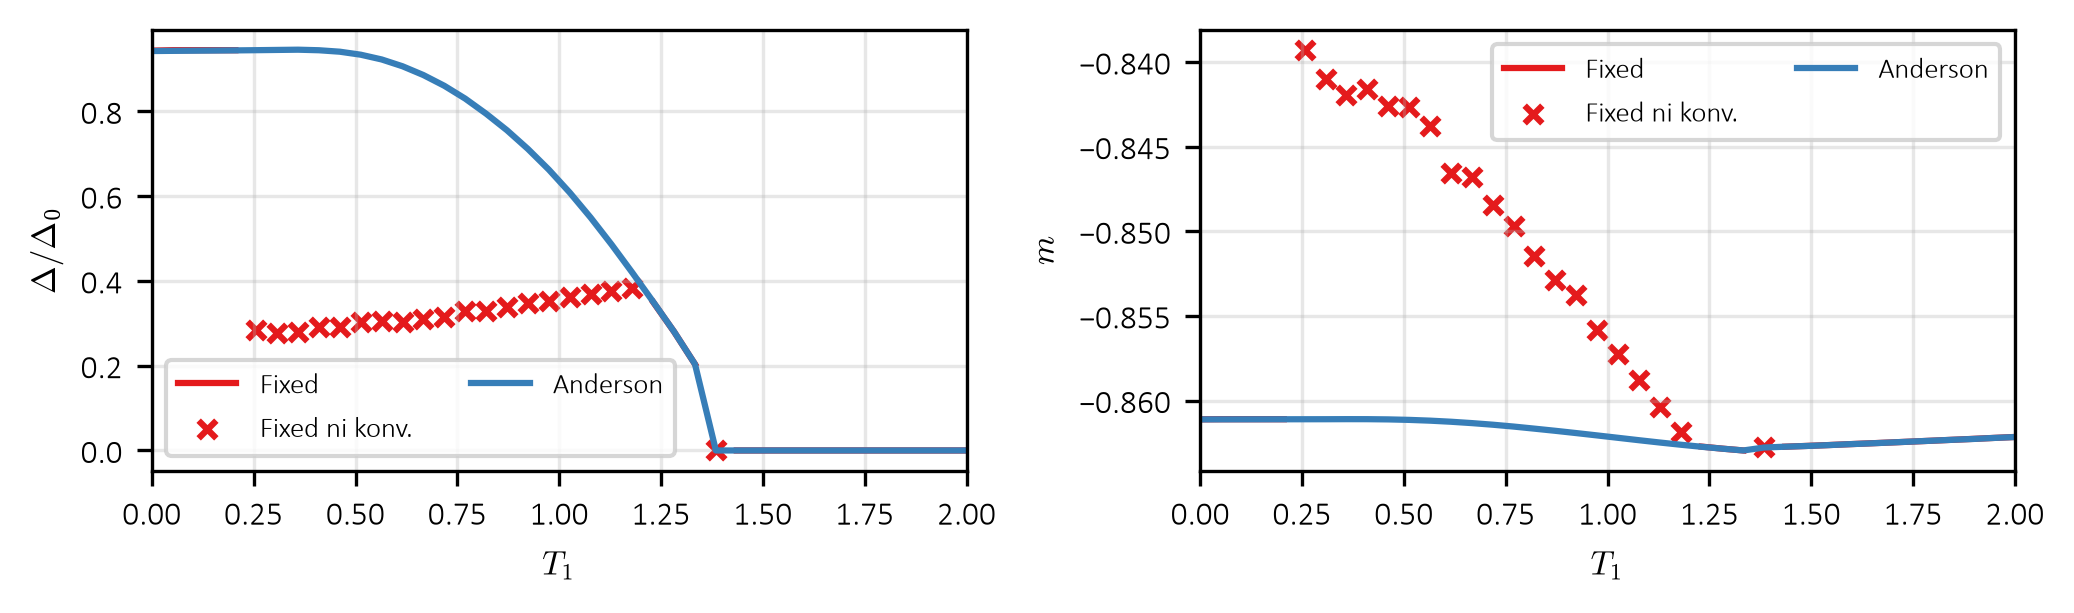

In [63]:
h = 0.6
fig, ax = plt.subplots(
    1, 2, sharex=True,
    figsize=(2*3.47412, h * 3.47412),
)

for j in tqdm(range(2), desc="Plot curves"):
    for a, y in zip(ax, (da[j] / float(d0), ma[j])):
        a.plot(
            ta/tc, np.where(ok[j], y, np.nan),
            color=SET1_LIST[j], label=labs[j],
        )
        if np.any(~ok[j]):
            a.scatter(
                ta[~ok[j]]/tc, y[~ok[j]],
                color=SET1_LIST[j], marker="x", s=18,
                label=f"{labs[j]} ni konv.",
            )

ax[0].set_ylabel(r"$\Delta/\Delta_0$")
ax[1].set_ylabel(r"$m$")
for a in tqdm(ax, desc="Format plots"):
    a.set_xlabel(r"$T_1$")
    a.set_xlim(ta[0]/tc, ta[-1]/tc)
    a.grid(alpha=0.3)
    a.legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.show()

In [ ]:
# ga = np.geomspace(0.05, 10.0, 1)   # gamma grid

# ss = [se, se]
# da = np.empty((2, ga.size))
# ma, er = np.empty_like(da), np.empty_like(da)
# ok = np.zeros(da.shape, dtype=bool)

# for i in tqdm(range(ga.size), desc="gamma sweep"):
#     bs = tuple(
#         fn(float(t), bd.k, name=f"bath_{j + 1}",
#            **{**bp, **o, "gam": float(ga[i])})
#         for j, (t, o) in enumerate(zip((t1, t2), ov))
#     )
#     for j in tqdm(range(2), desc="Solvers", leave=False):
#         s = ss[j]
#         s = fs[j](bd, p, s.n.copy(), bs,
#                   d=float(s.d), m=float(s.m), **ks[j])
#         if j == 1 and abs(float(s.d)) < ds and chi(s) > 1.0:
#             w0 = ej.solve_fixed(bd, p, s.n.copy(), bs, d=ds,
#                                 m=float(s.m), **{**kf, "nmax": nw})
#             s = fs[j](bd, p, w0.n.copy(), bs, d=float(w0.d),
#                       m=float(w0.m), **ks[j])
#         da[j, i], ma[j, i], er[j, i] = s.d, s.m, s.err
#         ok[j, i] = bool(s.ok) and np.isfinite(s.err) and s.err < ka["tol"]
#         ss[j] = s

In [ ]:
# import matplotlib.ticker as ticker
# with pt.figure(name="gap_vs_gam", shape=(1, 2), h=0.6, w=2.0) as q:
#     for j in range(2):
#         c = SET1_LIST[j + 1]
#         q.ax[0].plot(ga, np.abs(da[j]) / abs(d0), color=c, lw=0.8,
#                      marker="o", ms=2, label=labs[j])
#         q.ax[1].plot(ga, ma[j], color=c, lw=0.8,
#                      marker="o", ms=2, label=labs[j])
#         # unconverged points as crosses
#         q.ax[0].scatter(ga[~ok[j]], np.abs(da[j, ~ok[j]]) / abs(d0),
#                         color=c, marker="x", s=12, zorder=3)
#         q.ax[1].scatter(ga[~ok[j]], ma[j, ~ok[j]],
#                         color=c, marker="x", s=12, zorder=3)
#     format_ax(q.ax[0], x=ga, xlabel=r"$\gamma$",
#               ylabel=r"$|\Delta|/\Delta_0$")
#     format_ax(q.ax[1], x=ga, xlabel=r"$\gamma$", ylabel=r"$m$")
#     q.ax[1].yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:.3f}"))
#     for a in q.ax:
#         a.set_xscale("log")
#     add_legend(q.ax[0], top=False, fontsize=7)
#     # plt.savefig(FIG_PATH + "gamma_D_m_sweep_BCS.pdf", bbox_inches="tight")

In [ ]:
t1r = np.linspace(0.01, 1.5, 10)    # T1 / Tc
t2r = np.linspace(0.01, 1.5, 10)    # T2 / Tc

dm = np.full((t2r.size, t1r.size), np.nan)    # Delta, rows = T2
mm, em = np.full_like(dm, np.nan), np.full_like(dm, np.nan)
ok = np.zeros(dm.shape, dtype=bool)

kf = {**sk, "prog": False}
s0 = se    # row seed, always at the low T1 end

for i in tqdm(range(t2r.size), desc="T2 sweep"):
    sv = s0
    for j in tqdm(range(t1r.size), desc="T1 sweep", leave=False):
        bq = tuple(
            fn(float(t), bd.k, name=f"bath_{b + 1}", **{**bp, **o})
            for b, (t, o) in enumerate(zip((t1r[j] * tc, t2r[i] * tc), ov))
        )
        # floor the seeded gap
        dg = max(abs(float(sv.d)), ds)
        sn = ej.solve_fixed(bd, p, sv.n.copy(), bq,
                            d=dg, m=float(sv.m), **kf)
        # retry from a warm-up if it fell to zero
        if abs(float(sn.d)) < ds and chi(sn) > 1.0:
            w0 = ej.solve_fixed(bd, p, sn.n.copy(), bq, d=ds,
                                m=float(sn.m), **{**kf, "nmax": nw})
            sn = ej.solve_fixed(bd, p, w0.n.copy(), bq, d=float(w0.d),
                                m=float(w0.m), **kf)
        dm[i, j], mm[i, j], em[i, j] = sn.d, sn.m, sn.err
        ok[i, j] = bool(sn.ok) and np.isfinite(sn.err) and sn.err < kf["tol"]
        if np.isfinite(sn.err):
            sv = sn
        if j == 0 and np.isfinite(sn.err):
            s0 = sn    # next row starts here

print("unconverged:", (~ok).sum(), "of", ok.size)

T2 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

T1 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

T1 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

T1 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

T1 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

T1 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

... (2 outputs left out)

T1 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

T1 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

T1 sweep:   0%|          | 0/10 [00:00<?, ?it/s]

unconverged: 4 of 100


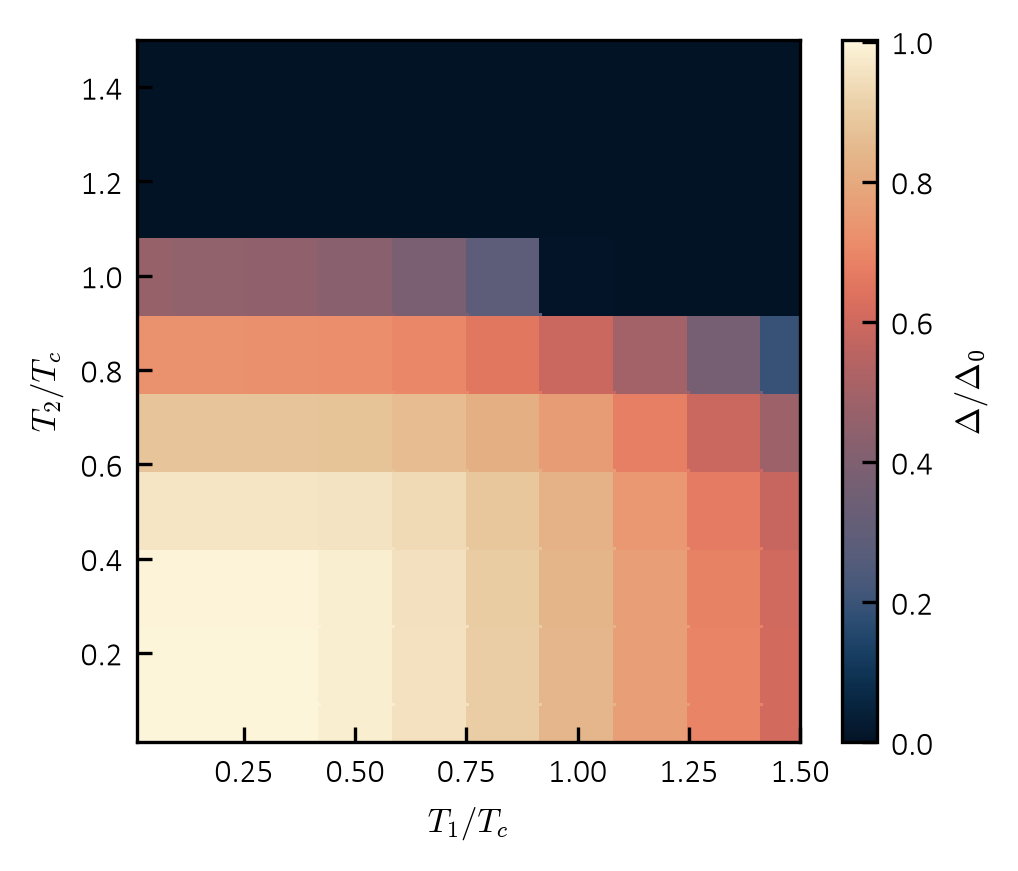

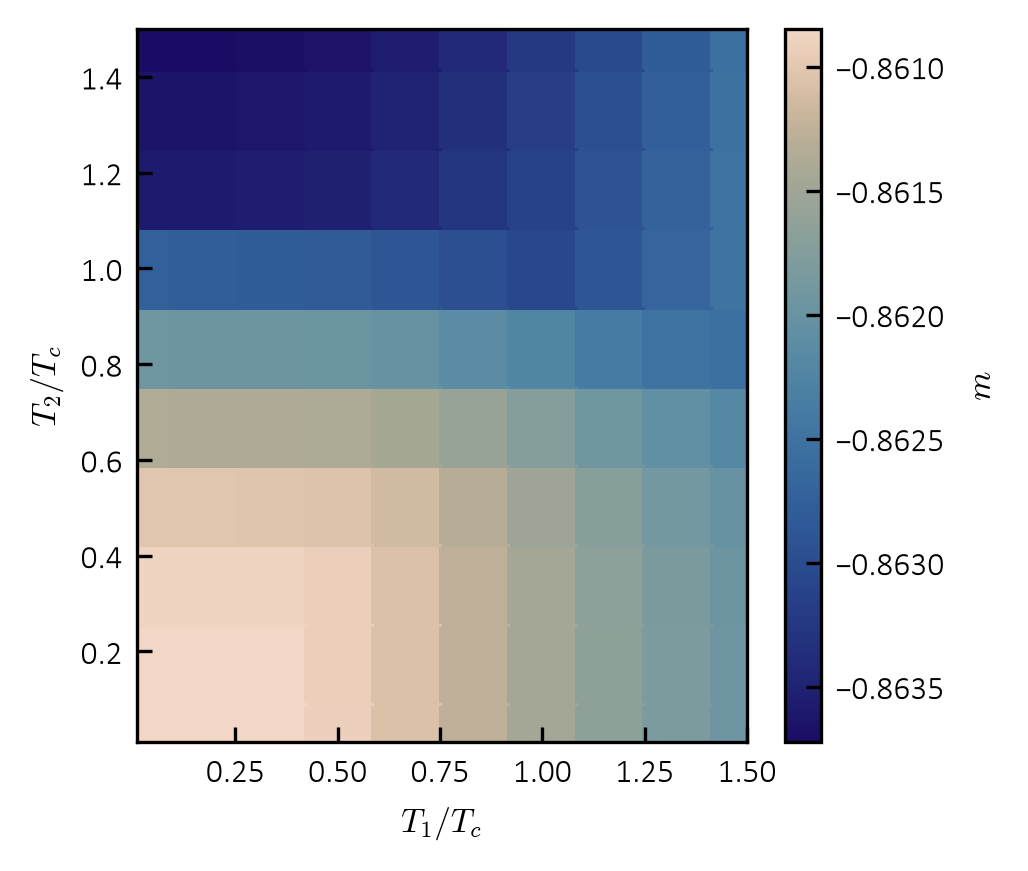

In [ ]:
dz = np.where(ok, np.abs(dm), np.nan) / d0
mz = np.where(ok, mm, np.nan)

fd, _ = plot_cmap(t1r, t2r, dm / d0, r"$\Delta/\Delta_0$", pt=pt)
# fd.savefig(FIG_PATH + "gap_map_test.pdf", bbox_inches="tight")

fm, _ = plot_cmap(t1r, t2r, mm, r"$m$", pt=pt,
                  cmap=cmaps.lapaz.cut(0.1, "right"))
# fm.savefig(FIG_PATH + "m_map_test.pdf", bbox_inches="tight")